# Thu nhập đầu người 2010–2014

**Ba câu hỏi**

1. Thu nhập thực bình quân đầu người có tăng không?
2. Thu nhập thực bình quân của từng Q1–Q4 có tăng không? Mức tăng nằm trong khoảng tin cậy 95% nào?
3. Thu nhập thực bình quân của thành thị và nông thôn có tăng không? Mức tăng nằm trong khoảng tin cậy 95% nào?

Phân tích hai bản trong cùng notebook: **giữ toàn mẫu** và **bỏ top 0,1% thu nhập đầu người trong từng năm**. Giữ nguyên nhãn Q trong Excel.

**Các bước:** đọc dữ liệu → quy về giá 2010 → xem phân phối Q4 → tạo hai bản mẫu → kiểm tra phân phối → kiểm định và CI 95% → đối chiếu kết quả.

## 1. Chuẩn bị

Nạp thư viện, chọn hai năm 2010 và 2014, đặt mức ý nghĩa α = 5%. Dùng dữ liệu Excel gốc và bảng CPI đã đối chiếu với Cục Thống kê.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

YEARS = [2010, 2014]
VERSIONS = ["Toàn mẫu", "Bỏ top 0,1%"]
GROUPS = ["Toàn mẫu", "Q1", "Q2", "Q3", "Q4", "Thành thị", "Nông thôn"]
AREA_CODES = {"Thành thị": 1, "Nông thôn": 2}
ALPHA = 0.05
TRIM_FRACTION = 0.001

project_directory = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "dataset/VHLSS_2014.xls").exists()
)
data_file = project_directory / "dataset/VHLSS_2014.xls"
output_directory = project_directory / "bao_cao_vhlss"
original_data_hash = hashlib.sha256(data_file.read_bytes()).hexdigest()
cpi = pd.read_csv(output_directory / "cpi_2010_2014.csv").set_index("nam")
cpi_by_year = cpi.loc[YEARS, "cpi_binh_quan_2010_bang_100"]
pd.set_option("display.max_columns", 20)

## 2. Thu nhập đầu người theo giá 2010

`income` là tổng thu nhập cả hộ trong năm, đơn vị nghìn đồng. `size` gồm tất cả thành viên, kể cả người chưa lao động.

\[
Y=\frac{income}{size}\times\frac{100}{CPI}\times\frac1{1000}.
\]

Đơn vị Y: **triệu đồng/người/năm, giá 2010**. CPI bình quân năm: 2010 = 100; 2014 = 143,69.

Mỗi dòng là một hộ/năm; mean là trung bình Y của các hộ, mỗi hộ có trọng số bằng nhau. Hai năm được coi là hai mẫu độc lập, không ghép cặp hộ. `area`: 1 = thành thị, 2 = nông thôn. Q1–Q4 là nhãn có sẵn, xác định riêng từng năm.

Bước này: kiểm tra thu nhập và quy mô hộ → tính Y → báo số dòng hợp lệ.

In [2]:
income_by_year = {}
data_audit_rows = []
for year in YEARS:
    raw_data = pd.read_excel(data_file, sheet_name=str(year))
    valid = (
        np.isfinite(raw_data["income"]) & raw_data["income"].ge(0)
        & np.isfinite(raw_data["size"]) & raw_data["size"].gt(0)
        & raw_data["Quart"].isin([1, 2, 3, 4])
    )
    households = raw_data.loc[valid, ["income", "size", "Quart", "area"]].copy()
    assert households["area"].isin(AREA_CODES.values()).all()
    households["excel_row"] = households.index + 2
    households["year"] = year
    households["income_per_person"] = (
        households["income"] / households["size"] / 1000 * 100 / cpi_by_year.loc[year]
    )
    income_by_year[year] = households
    data_audit_rows.append({
        "Năm": year, "CPI": cpi_by_year.loc[year], "Số dòng gốc": len(raw_data),
        "Hợp lệ": len(households), "Không hợp lệ": int((~valid).sum()),
    })
display(pd.DataFrame(data_audit_rows))

,Năm,CPI,Số dòng gốc,Hợp lệ,Không hợp lệ
0,2010,100.00,9399,9399,0
1,2014,143.69,9398,9398,0


## 3. Phân phối Q4 trước khi lọc

Biểu đồ dùng **toàn bộ Q4 gốc**. Các chấm đỏ là 10 hộ nằm trong top 0,1% của toàn năm. Hàng trên giữ trục thu nhập tuyến tính và cùng giới hạn giữa hai năm; hàng dưới dùng trục thu nhập log để nhìn rõ cả phần tập trung và đuôi phải. Log chỉ dùng khi vẽ, không dùng trong kiểm định.

Bước này: sắp thu nhập Q4 → đánh dấu top 0,1% → so mean với median và xem ảnh hưởng của đuôi trên. Các quan sát lớn là lý do làm thêm bản phân tích độ nhạy, không tự động được coi là lỗi.

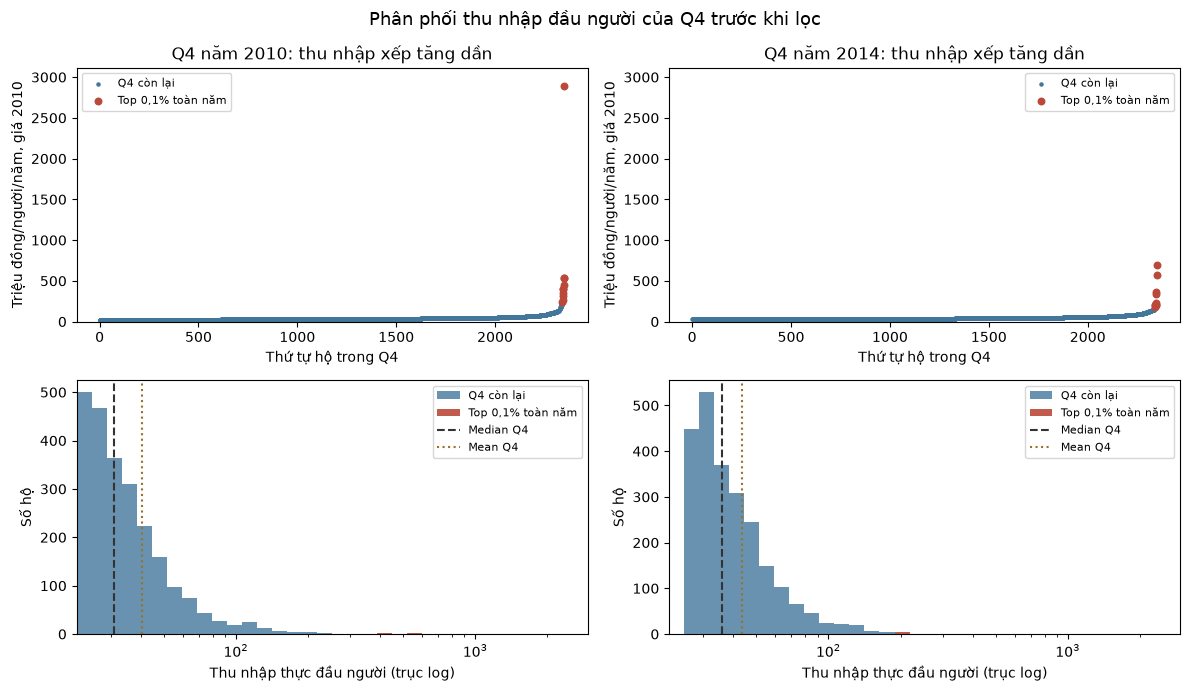

,Năm,Số hộ Q4,Mean,Median,Lớn nhất,Skewness,"SS do top 0,1% (%)"
0,2010,2350,40.293,30.928,2885.183,34.200,89.303
1,2014,2349,43.390,35.876,698.378,9.809,53.630


Top 0,1% đóng góp **89.3%** tổng bình phương độ lệch của Q4 năm 2010 và **53.6%** năm 2014. Đuôi trên ảnh hưởng mạnh đến mean và SE; vì vậy tính cả bản toàn mẫu và bản bỏ top 0,1%.

In [3]:
figure, axes = plt.subplots(2, 2, figsize=(12, 7))
q4_chart_rows = []
q4_max = max(data.loc[data["Quart"].eq(4), "income_per_person"].max()
             for data in income_by_year.values())
q4_min = min(data.loc[data["Quart"].eq(4), "income_per_person"].min()
             for data in income_by_year.values())
bins = np.geomspace(q4_min * .98, q4_max * 1.02, 35)

for column, year in enumerate(YEARS):
    data = income_by_year[year]
    q4_income = data.loc[data["Quart"].eq(4), "income_per_person"].sort_values()
    number_to_remove = int(np.ceil(TRIM_FRACTION * len(data)))
    top_income = data.nlargest(number_to_remove, "income_per_person")["income_per_person"]
    top_mask = q4_income.index.isin(top_income.index)
    ranks = np.arange(1, len(q4_income) + 1)
    squared_deviations = (q4_income - q4_income.mean())**2
    top_ss_percent = 100 * squared_deviations.loc[top_income.index].sum() / squared_deviations.sum()

    axis = axes[0, column]
    axis.scatter(ranks[~top_mask], q4_income.loc[~top_mask], s=5, color="#42779b", label="Q4 còn lại")
    axis.scatter(ranks[top_mask], q4_income.loc[top_mask], s=22, color="#bb4939", label="Top 0,1% toàn năm")
    axis.set(title=f"Q4 năm {year}: thu nhập xếp tăng dần", xlabel="Thứ tự hộ trong Q4",
             ylabel="Triệu đồng/người/năm, giá 2010", ylim=(0, q4_max * 1.08))
    axis.legend(fontsize=8)

    axis = axes[1, column]
    axis.hist(q4_income.loc[~top_mask], bins=bins, color="#42779b", alpha=.8, label="Q4 còn lại")
    axis.hist(q4_income.loc[top_mask], bins=bins, color="#bb4939", alpha=.9, label="Top 0,1% toàn năm")
    axis.axvline(q4_income.median(), color="#333333", linestyle="--", label="Median Q4")
    axis.axvline(q4_income.mean(), color="#99702d", linestyle=":", label="Mean Q4")
    axis.set_xscale("log")
    axis.set(xlabel="Thu nhập thực đầu người (trục log)", ylabel="Số hộ",
             xlim=(bins[0], bins[-1]))
    axis.legend(fontsize=8)
    q4_chart_rows.append({
        "Năm": year, "Số hộ Q4": len(q4_income), "Mean": q4_income.mean(),
        "Median": q4_income.median(), "Lớn nhất": q4_income.max(),
        "Skewness": stats.skew(q4_income), "SS do top 0,1% (%)": top_ss_percent,
    })

figure.suptitle("Phân phối thu nhập đầu người của Q4 trước khi lọc", fontsize=13)
figure.tight_layout()
figure.savefig(output_directory / "q4_phan_phoi_thu_nhap.png", dpi=160)
plt.show()
q4_description = pd.DataFrame(q4_chart_rows)
display(q4_description.round(3))
display(Markdown(
    f"Top 0,1% đóng góp **{q4_description.iloc[0]['SS do top 0,1% (%)']:.1f}%** "
    f"tổng bình phương độ lệch của Q4 năm 2010 và **{q4_description.iloc[1]['SS do top 0,1% (%)']:.1f}%** năm 2014. "
    "Đuôi trên ảnh hưởng mạnh đến mean và SE; vì vậy tính cả bản toàn mẫu và bản bỏ top 0,1%."
))

## 4. Tạo hai bản mẫu

- **Toàn mẫu:** giữ mọi hộ có dữ liệu hợp lệ.
- **Bỏ top 0,1%:** xếp Y giảm dần trong toàn năm, bỏ $k=\lceil0,001n\rceil=10$ hộ cao nhất mỗi năm. Sau đó mới phân tổ theo Q và khu vực; không cắt riêng 0,1% trong từng nhóm.

Bước này: xác định 10 hộ cao nhất → bỏ đúng các dòng đó → giữ nhãn Q và khu vực → kiểm tra số hộ. Bản sau lọc trả lời về phần hộ ngoài top 0,1%; bộ lọc và nhãn Q được coi như đã cho trong phép tính SE.

In [4]:
analysis_data = {}
removed_by_year = {}
sample_audit_rows = []
for year in YEARS:
    ordered = income_by_year[year].sort_values("income_per_person", ascending=False)
    number_to_remove = int(np.ceil(TRIM_FRACTION * len(ordered)))
    removed = ordered.iloc[:number_to_remove].copy()
    retained = ordered.iloc[number_to_remove:].copy()
    assert removed["income_per_person"].min() > retained["income_per_person"].max()
    removed_by_year[year] = removed
    analysis_data[("Toàn mẫu", year)] = income_by_year[year]
    analysis_data[("Bỏ top 0,1%", year)] = retained
    for version in VERSIONS:
        current = analysis_data[(version, year)]
        sample_audit_rows.append({
            "Mẫu": version, "Năm": year, "Số hộ": len(current),
            "Đã loại": len(ordered) - len(current),
            "Q4": int(current["Quart"].eq(4).sum()),
            "Thành thị": int(current["area"].eq(1).sum()),
            "Nông thôn": int(current["area"].eq(2).sum()),
        })
sample_audit = pd.DataFrame(sample_audit_rows)
removed_households = pd.concat(removed_by_year.values(), ignore_index=True)
display(sample_audit)

def group_values(data, group):
    if group == "Toàn mẫu":
        return data["income_per_person"].to_numpy()
    if group.startswith("Q"):
        return data.loc[data["Quart"].eq(int(group[1:])), "income_per_person"].to_numpy()
    return data.loc[data["area"].eq(AREA_CODES[group]), "income_per_person"].to_numpy()

,Mẫu,Năm,Số hộ,Đã loại,Q4,Thành thị,Nông thôn
0,Toàn mẫu,2010,9399,0,2350,2649,6750
1,"Bỏ top 0,1%",2010,9389,10,2340,2643,6746
2,Toàn mẫu,2014,9398,0,2349,2781,6617
3,"Bỏ top 0,1%",2014,9388,10,2339,2775,6613


## 5. Kiểm tra phân phối — Chap 9, mục 9.4, trang 21

Trong từng mẫu năm × phạm vi: **H₀: Y có phân phối chuẩn; H₁: Y không có phân phối chuẩn.** Dùng Jarque–Bera:

\[
JB=n\left(\frac{Skew^2}{6}+\frac{(Kurt-3)^2}{24}\right)\approx\chi^2_2.
\]

Bước này: lấy các mẫu đúng phạm vi → tính skewness, kurtosis, JB → so với ngưỡng $\chi^2_{2;0,95}$. Đồng thời xem tỷ trọng SS của một quan sát lớn nhất để nhận diện mẫu bị chi phối mạnh.

Kiểm tra này nói về **dữ liệu hộ**, không phải phân phối của estimator. Mean vẫn là estimator cho thu nhập bình quân. Kiểm định t bên dưới là xấp xỉ theo Chap 3 và Chap 7; cỡ mẫu lớn không tự bảo đảm xấp xỉ tốt khi một quan sát chi phối phương sai.

In [5]:
samples = {}
distribution_rows = []
for version in VERSIONS:
    for year in YEARS:
        for group in GROUPS:
            values = group_values(analysis_data[(version, year)], group)
            samples[(version, year, group)] = values
            skewness = stats.skew(values)
            excess_kurtosis = stats.kurtosis(values)
            jb_statistic = len(values) * (skewness**2 / 6 + excess_kurtosis**2 / 24)
            squared_deviations = (values - values.mean())**2
            distribution_rows.append({
                "Mẫu": version, "Năm": year, "Nhóm": group, "n": len(values),
                "Skewness": skewness, "JB": jb_statistic,
                "Bác bỏ chuẩn": bool(jb_statistic > stats.chi2.ppf(.95, 2)),
                "SS lớn nhất (%)": 100 * squared_deviations.max() / squared_deviations.sum(),
            })
distribution_check = pd.DataFrame(distribution_rows)
display(distribution_check.round(3))
display(Markdown(
    "**Nhận xét:** dữ liệu sau lọc vẫn bác bỏ chuẩn. Đặc biệt, bản toàn mẫu năm 2010 có đuôi rất lớn "
    "ở Q4 và nông thôn, nên p/CI của các mean liên quan cần đọc cùng kết quả sau lọc. "
    "Bỏ top 0,1% giảm ảnh hưởng đuôi nhưng không làm dữ liệu trở thành chuẩn."
))

,Mẫu,Năm,Nhóm,n,Skewness,JB,Bác bỏ chuẩn,SS lớn nhất (%)
0,Toàn mẫu,2010,Toàn mẫu,9399,56.001,7.444431e+09,True,67.987
1,Toàn mẫu,2010,Q1,2350,-0.334,1.111140e+02,True,0.366
2,Toàn mẫu,2010,Q2,2349,0.053,1.296190e+02,True,0.143
3,Toàn mẫu,2010,Q3,2350,0.252,1.541740e+02,True,0.155
4,Toàn mẫu,2010,Q4,2350,34.200,2.011307e+08,True,78.007
5,Toàn mẫu,2010,Thành thị,2649,5.704,3.580947e+05,True,7.578
6,Toàn mẫu,2010,Nông thôn,6750,62.570,5.945556e+09,True,82.430
7,Toàn mẫu,2014,Toàn mẫu,9398,9.126,1.855311e+07,True,11.977
8,Toàn mẫu,2014,Q1,2352,-0.215,1.125460e+02,True,0.309
9,Toàn mẫu,2014,Q2,2350,0.043,1.408360e+02,True,0.130


**Nhận xét:** dữ liệu sau lọc vẫn bác bỏ chuẩn. Đặc biệt, bản toàn mẫu năm 2010 có đuôi rất lớn ở Q4 và nông thôn, nên p/CI của các mean liên quan cần đọc cùng kết quả sau lọc. Bỏ top 0,1% giảm ảnh hưởng đuôi nhưng không làm dữ liệu trở thành chuẩn.

## 6. Công thức kiểm định và khoảng tin cậy

**Phương pháp chung — Chap 7 §7.2.4, trang 14:** t-test hai mẫu độc lập, phương sai tổng thể chưa biết và không giả sử bằng nhau. Lấy mẫu 1 là năm 2014, mẫu 2 là năm 2010, cùng phạm vi.

Tham số $\Delta_g=\mu_{g,2014}-\mu_{g,2010}$; estimator $\widehat\Delta_g=\bar Y_{g,2014}-\bar Y_{g,2010}$ (Lecture 4). Với mọi câu hỏi: **H₀: Δg=0; H₁: Δg>0**.

\[
SE=\sqrt{\frac{S_{14}^2}{n_{14}}+\frac{S_{10}^2}{n_{10}}},\qquad
T=\frac{\widehat\Delta_g}{SE},\qquad
\nu=\frac{(S_{14}^2/n_{14}+S_{10}^2/n_{10})^2}
{(S_{14}^2/n_{14})^2/(n_{14}-1)+(S_{10}^2/n_{10})^2/(n_{10}-1)}.
\]

Dưới H₀, $T\approx t_\nu$. Kiểm định một phía phải: $p=P(t_\nu\ge T)$; bác bỏ H₀ nếu p < 0,05.

\[
CI_{95\%}(\Delta_g)=\widehat\Delta_g\pm t_{\nu;0,975}SE.
\]

CI báo **hai phía cho chênh lệch mean**, không phải khoảng chứa 95% số hộ. Các p và CI áp dụng riêng từng phép so sánh, không phải kết quả đồng thời cho mọi nhóm.

Bước tính: lấy hai mẫu → n, mean và S² (mẫu số n−1) → chênh lệch mean → SE và bậc tự do → t và p phía phải → CI 95% → quyết định.

In [6]:
def compare_means(earlier, later):
    earlier_n, later_n = len(earlier), len(later)
    earlier_mean, later_mean = earlier.mean(), later.mean()
    earlier_part = earlier.var(ddof=1) / earlier_n
    later_part = later.var(ddof=1) / later_n
    change = later_mean - earlier_mean
    standard_error = np.sqrt(earlier_part + later_part)
    degrees_of_freedom = (earlier_part + later_part)**2 / (
        earlier_part**2 / (earlier_n - 1) + later_part**2 / (later_n - 1)
    )
    statistic = change / standard_error
    p_value = stats.t.sf(statistic, degrees_of_freedom)
    margin = stats.t.ppf(.975, degrees_of_freedom) * standard_error
    return {
        "n 2010": earlier_n, "n 2014": later_n,
        "Mean 2010": earlier_mean, "Mean 2014": later_mean,
        "Tăng": change, "Tăng (%)": 100 * change / earlier_mean,
        "SE": standard_error, "t": statistic, "df": degrees_of_freedom,
        "p phía phải": p_value, "CI95 dưới": change - margin, "CI95 trên": change + margin,
        "Quyết định": "Bác bỏ H₀" if p_value < ALPHA else "Không bác bỏ H₀",
    }

result_rows = []
for version in VERSIONS:
    for group in GROUPS:
        result = compare_means(samples[(version, 2010, group)], samples[(version, 2014, group)])
        result_rows.append({"Mẫu": version, "Nhóm": group, **result})
results = pd.DataFrame(result_rows)

def show_results(rows):
    table = rows[["Nhóm", "n 2010", "n 2014", "Mean 2010", "Mean 2014", "Tăng", "Tăng (%)", "p phía phải", "Quyết định"]].copy()
    table["CI 95% của mức tăng"] = [
        f"[{low:.3f}; {high:.3f}]" for low, high in zip(rows["CI95 dưới"], rows["CI95 trên"])
    ]
    display(table.style.hide(axis="index").format({
        "Mean 2010": "{:.3f}", "Mean 2014": "{:.3f}", "Tăng": "{:.3f}", "Tăng (%)": "{:.2f}",
        "p phía phải": lambda value: "<1e-300" if value == 0 else f"{value:.3e}",
    }))

## 7. Câu 1 — Thu nhập bình quân đầu người có tăng không?

- **Tham số:** $\Delta=\mu_{2014}-\mu_{2010}$ của phạm vi toàn mẫu trong từng bản.
- **H₀: Δ=0; H₁: Δ>0.** Dùng t-test độc lập, phương sai chưa biết và không giả sử bằng nhau, phía phải — Chap 7 §7.2.4.
- **Mẫu:** mọi hộ hợp lệ của hai năm; ở bản lọc, bỏ 10 hộ cao nhất mỗi năm trước khi tính mean.
- **Các bước:** lấy hai mẫu toàn năm → chênh lệch mean → t/p và CI 95% → đối chiếu hai bản.

In [7]:
for version in VERSIONS:
    display(Markdown(f"**{version}**"))
    row = results.loc[results["Mẫu"].eq(version) & results["Nhóm"].eq("Toàn mẫu")]
    show_results(row)
    estimate = row.iloc[0]
    display(Markdown(
        f"Thu nhập thực bình quân tăng **{estimate['Tăng']:.3f} triệu/người/năm "
        f"({estimate['Tăng (%)']:.2f}%)**; CI 95% của mức tăng: "
        f"**[{estimate['CI95 dưới']:.3f}; {estimate['CI95 trên']:.3f}] triệu**. "
        f"{estimate['Quyết định']} ở mức 5% theo kiểm định xấp xỉ."
    ))

**Toàn mẫu**

Nhóm,n 2010,n 2014,Mean 2010,Mean 2014,Tăng,Tăng (%),p phía phải,Quyết định,CI 95% của mức tăng
Toàn mẫu,9399,9398,18.257,20.861,2.604,14.26,4.445e-10,Bác bỏ H₀,[1.771; 3.436]


Thu nhập thực bình quân tăng **2.604 triệu/người/năm (14.26%)**; CI 95% của mức tăng: **[1.771; 3.436] triệu**. Bác bỏ H₀ ở mức 5% theo kiểm định xấp xỉ.

**Bỏ top 0,1%**

Nhóm,n 2010,n 2014,Mean 2010,Mean 2014,Tăng,Tăng (%),p phía phải,Quyết định,CI 95% của mức tăng
Toàn mẫu,9389,9388,17.598,20.543,2.944,16.73,5.617e-34,Bác bỏ H₀,[2.468; 3.421]


Thu nhập thực bình quân tăng **2.944 triệu/người/năm (16.73%)**; CI 95% của mức tăng: **[2.468; 3.421] triệu**. Bác bỏ H₀ ở mức 5% theo kiểm định xấp xỉ.

## 8. Câu 2 — Thu nhập bình quân trong từng Q1–Q4 có tăng không?

Với mỗi q = 1, 2, 3, 4: **H₀: μq,2014 − μq,2010 = 0; H₁: μq,2014 − μq,2010 > 0.**

Dùng t-test độc lập, phương sai chưa biết và không giả sử bằng nhau, phía phải — Chap 7 §7.2.4. Mẫu là các hộ mang nhãn Q tương ứng của từng năm, không phải cùng hộ qua thời gian. Q4 sau lọc là phần còn lại của Q4 gốc.

Các bước: phân tổ bằng nhãn Q gốc → lấy hai mẫu mỗi Q → tính mức tăng và CI 95% → kiểm định riêng từng Q → đối chiếu hai bản. Không suy Q nào tăng nhanh hơn từ việc so các p.

In [8]:
for version in VERSIONS:
    display(Markdown(f"**{version}**"))
    rows = results.loc[results["Mẫu"].eq(version) & results["Nhóm"].isin(["Q1", "Q2", "Q3", "Q4"])]
    show_results(rows)
    rejected = rows.loc[rows["Quyết định"].eq("Bác bỏ H₀"), "Nhóm"].tolist()
    display(Markdown(
        "Theo từng kiểm định ở mức 5%, có bằng chứng mean tăng ở **" + ", ".join(rejected) + "**. "
        "Các khoảng trong bảng ước lượng mức tăng của từng nhóm, đơn vị triệu đồng/người/năm, giá 2010."
    ))

**Toàn mẫu**

Nhóm,n 2010,n 2014,Mean 2010,Mean 2014,Tăng,Tăng (%),p phía phải,Quyết định,CI 95% của mức tăng
Q1,2350,2352,5.257,6.292,1.035,19.69,3.043e-81,Bác bỏ H₀,[0.931; 1.139]
Q2,2349,2350,10.382,13.024,2.642,25.45,<1e-300,Bác bỏ H₀,[2.542; 2.742]
Q3,2350,2347,17.093,20.758,3.665,21.44,<1e-300,Bác bỏ H₀,[3.514; 3.816]
Q4,2350,2349,40.293,43.390,3.097,7.69,1.919e-02,Bác bỏ H₀,[0.166; 6.029]


Theo từng kiểm định ở mức 5%, có bằng chứng mean tăng ở **Q1, Q2, Q3, Q4**. Các khoảng trong bảng ước lượng mức tăng của từng nhóm, đơn vị triệu đồng/người/năm, giá 2010.

**Bỏ top 0,1%**

Nhóm,n 2010,n 2014,Mean 2010,Mean 2014,Tăng,Tăng (%),p phía phải,Quyết định,CI 95% của mức tăng
Q1,2350,2352,5.257,6.292,1.035,19.69,3.043e-81,Bác bỏ H₀,[0.931; 1.139]
Q2,2349,2350,10.382,13.024,2.642,25.45,<1e-300,Bác bỏ H₀,[2.542; 2.742]
Q3,2350,2347,17.093,20.758,3.665,21.44,<1e-300,Bác bỏ H₀,[3.514; 3.816]
Q4,2340,2339,37.744,42.210,4.467,11.83,8.931e-14,Bác bỏ H₀,[3.281; 5.652]


Theo từng kiểm định ở mức 5%, có bằng chứng mean tăng ở **Q1, Q2, Q3, Q4**. Các khoảng trong bảng ước lượng mức tăng của từng nhóm, đơn vị triệu đồng/người/năm, giá 2010.

## 9. Câu 3 — Thu nhập bình quân thành thị và nông thôn có tăng không?

Với mỗi khu vực a: **H₀: μa,2014 − μa,2010 = 0; H₁: μa,2014 − μa,2010 > 0.**

Dùng t-test độc lập, phương sai chưa biết và không giả sử bằng nhau, phía phải — Chap 7 §7.2.4. Một phép so sánh dùng hai mẫu **thành thị qua hai năm**; phép còn lại dùng hai mẫu **nông thôn qua hai năm**. Không kiểm định thành thị so với nông thôn trong cùng năm.

Các bước: phân tổ bằng `area` → lấy hai mẫu mỗi khu vực → tính mức tăng và CI 95% → kiểm định riêng từng khu vực → đối chiếu hai bản. Bộ lọc top 0,1% áp dụng toàn năm trước khi phân tổ.

In [9]:
for version in VERSIONS:
    display(Markdown(f"**{version}**"))
    rows = results.loc[results["Mẫu"].eq(version) & results["Nhóm"].isin(AREA_CODES)]
    show_results(rows)
    for _, estimate in rows.iterrows():
        display(Markdown(
            f"**{estimate['Nhóm']}:** tăng ước lượng **{estimate['Tăng']:.3f} triệu/người/năm**; "
            f"CI 95% **[{estimate['CI95 dưới']:.3f}; {estimate['CI95 trên']:.3f}] triệu**. "
            f"{estimate['Quyết định']} ở mức 5% theo kiểm định xấp xỉ."
        ))

**Toàn mẫu**

Nhóm,n 2010,n 2014,Mean 2010,Mean 2014,Tăng,Tăng (%),p phía phải,Quyết định,CI 95% của mức tăng
Thành thị,2649,2781,27.089,29.532,2.444,9.02,1.662e-04,Bác bỏ H₀,[1.110; 3.778]
Nông thôn,6750,6617,14.791,17.216,2.425,16.39,1.193e-06,Bác bỏ H₀,[1.418; 3.432]


**Thành thị:** tăng ước lượng **2.444 triệu/người/năm**; CI 95% **[1.110; 3.778] triệu**. Bác bỏ H₀ ở mức 5% theo kiểm định xấp xỉ.

**Nông thôn:** tăng ước lượng **2.425 triệu/người/năm**; CI 95% **[1.418; 3.432] triệu**. Bác bỏ H₀ ở mức 5% theo kiểm định xấp xỉ.

**Bỏ top 0,1%**

Nhóm,n 2010,n 2014,Mean 2010,Mean 2014,Tăng,Tăng (%),p phía phải,Quyết định,CI 95% của mức tăng
Thành thị,2643,2775,26.406,28.965,2.559,9.69,2.681e-06,Bác bỏ H₀,[1.458; 3.661]
Nông thôn,6746,6613,14.147,17.008,2.861,20.22,6.962e-36,Bác bỏ H₀,[2.412; 3.310]


**Thành thị:** tăng ước lượng **2.559 triệu/người/năm**; CI 95% **[1.458; 3.661] triệu**. Bác bỏ H₀ ở mức 5% theo kiểm định xấp xỉ.

**Nông thôn:** tăng ước lượng **2.861 triệu/người/năm**; CI 95% **[2.412; 3.310] triệu**. Bác bỏ H₀ ở mức 5% theo kiểm định xấp xỉ.

## 10. Kiểm tra kết quả và lưu bảng

Đối chiếu t, bậc tự do, p và CI với SciPy; kiểm tra hai bản chỉ khác đúng 10 hộ mỗi năm, giữ nguyên Q1–Q3 và các mã phân nhóm. Các bảng CSV lưu đủ SE, t, df, p và hai đầu CI để kiểm tra từ code.

Kết luận giới hạn ở thu nhập thực bình quân trong hai phạm vi mẫu. Chưa xét trọng số/tầng/cụm khảo sát hoặc giá riêng từng vùng; kết quả không có nghĩa mọi hộ đều tăng thu nhập. Bản toàn mẫu chịu ảnh hưởng đuôi lớn; bản lọc dùng công thức lớp với bộ lọc được coi như đã cố định.

In [10]:
for (version, year), data in analysis_data.items():
    assert sum(len(group_values(data, f"Q{q}")) for q in [1, 2, 3, 4]) == len(data)
    assert sum(len(group_values(data, area)) for area in AREA_CODES) == len(data)
for year in YEARS:
    original = income_by_year[year]
    retained = analysis_data[("Bỏ top 0,1%", year)]
    removed = removed_by_year[year]
    assert len(removed) == 10 and removed["Quart"].eq(4).all()
    assert set(retained.index).isdisjoint(removed.index)
    assert set(retained.index) | set(removed.index) == set(original.index)
    for group in ["Q1", "Q2", "Q3"]:
        np.testing.assert_allclose(
            np.sort(group_values(original, group)), np.sort(group_values(retained, group))
        )
for _, row in results.iterrows():
    earlier = samples[(row["Mẫu"], 2010, row["Nhóm"])]
    later = samples[(row["Mẫu"], 2014, row["Nhóm"])]
    reference = stats.ttest_ind(later, earlier, equal_var=False, alternative="greater")
    interval = stats.ttest_ind(later, earlier, equal_var=False).confidence_interval(.95)
    np.testing.assert_allclose([row["t"], row["df"]], [reference.statistic, reference.df])
    np.testing.assert_allclose(row["p phía phải"], reference.pvalue, atol=0, rtol=1e-10)
    np.testing.assert_allclose([row["CI95 dưới"], row["CI95 trên"]], [interval.low, interval.high])
for _, row in distribution_check.iterrows():
    reference = stats.jarque_bera(samples[(row["Mẫu"], row["Năm"], row["Nhóm"])])
    np.testing.assert_allclose(row["JB"], reference.statistic)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == original_data_hash

results.to_csv(output_directory / "thu_nhap_ket_qua.csv", index=False)
sample_audit.to_csv(output_directory / "thu_nhap_so_mau.csv", index=False)
distribution_check.to_csv(output_directory / "thu_nhap_phan_phoi.csv", index=False)
removed_households.to_csv(output_directory / "thu_nhap_top_0_1.csv", index=False)
print("Đã đối chiếu 14 phép kiểm định và CI 95%, 28 mẫu phân phối và bộ lọc. Dữ liệu gốc giữ nguyên.")

Đã đối chiếu 14 phép kiểm định và CI 95%, 28 mẫu phân phối và bộ lọc. Dữ liệu gốc giữ nguyên.
